# Case: Detecção de fraude
##### 1. Análise exploratória e Feature tests
Autora: Ana Clara Fernandes

In [ ]:
#pip install contextily

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact, chi2_contingency
from scipy.stats import spearmanr
from matplotlib.colors import LinearSegmentedColormap
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
import geopandas as gpd
import contextily as cx


In [2]:
df = pd.read_csv("nuvem_fraud_dataset.csv", sep =";", decimal = ",")

In [3]:
#trata lat long
for c in ["lat", "long", "store_lat", "store_long"]:
    df[c] = df[c].astype(str).str.replace("|", ".", regex=False).astype(float)

In [4]:
# Variáveis derivadas


df['created_at'] = pd.to_datetime(df['created_at'])
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'])

#lat-long puro nao diz muita coisa, mas a distancia entre cliente e loja, sim
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df['dist_km'] = haversine_km(df['lat'], df['long'], df['store_lat'], df['store_long'])

#Data de nascimento sozinha nao me diz mto, mas IDADE NO MOMENTO DA COMPRA, sim.
df['age'] = (df['created_at'] - df['date_of_birth']).dt.days / 365.25

# Hora da compra é uma variável clássica em modelos de fraude, com dummie de madrugada entre 22h e 5 da manha, geralmente.
df['hour'] = df['created_at'].dt.hour
df['flag_noite'] = df['hour'].isin([22, 23, 0, 1, 2, 3, 4, 5]).astype(int)

#variáveis deerivadas do dia da compra:
df['dia_semana'] = df['created_at'].dt.dayofweek
df['fim_semana'] = (df['dia_semana'] >= 5).astype(int)

#logs, para testar
df['log_amount'] = np.log1p(df['amount'])
df['log_city_pop'] = np.log1p(df['city_population'])

In [5]:
# Imputação State a partir de city
# ainda sobram 10 linhas 
nulos = df['state'].isna()
print('Linhas com state nulo:', nulos.sum(), '| com city também nula:', (nulos & df['city'].isna()).sum())

# Quantos estados distintos cada nome de cidade tem (só linhas com state)
estados_por_cidade = df.loc[~nulos].groupby('city')['state'].nunique()
print('Cidades com mais de 1 estado (ambíguas):', (estados_por_cidade > 1).sum())

# Mapa city -> state, apenas para nomes não ambíguos
mapa = (df.loc[~nulos].groupby('city')['state']
          .agg(lambda s: s.iloc[0] if s.nunique() == 1 else np.nan))

df['state_origem'] = np.where(~nulos, 'original', 'imputado')
df['state'] = df['state'].fillna(df['city'].map(mapa))

# O que não foi resolvido (cidade ambígua ou sem nenhuma linha com estado)
nao_res = df['state'].isna()
df.loc[nao_res, 'state_origem'] = 'nao_resolvido'
print(df['state_origem'].value_counts())

Linhas com state nulo: 943 | com city também nula: 0
Cidades com mais de 1 estado (ambíguas): 1
state_origem
original         340576
imputado            933
nao_resolvido        10
Name: count, dtype: int64


In [6]:
nr = df[df['state_origem'] == 'nao_resolvido']

print('Linhas:', len(nr))
print('Fraudes:', int(nr['is_fraud'].sum()))
print(f"Taxa: {nr['is_fraud'].mean() * 100:.1f}%  |  taxa basal da base: {df['is_fraud'].mean() * 100:.3f}%")

# Por que não resolveram? (cidade ausente, ou nome ambíguo)
nr = nr.assign(
    motivo=np.where(nr['city'].isna(), 'city nula',
            np.where(nr['city'].isin(estados_por_cidade[estados_por_cidade > 1].index),
                     'cidade ambígua', 'cidade sem nenhuma linha com state'))
)
print(nr['motivo'].value_counts())

display(nr[['created_at', 'city', 'city_population', 'lat', 'long',
            'vertical', 'amount', 'is_fraud', 'motivo']]
        .sort_values('is_fraud', ascending=False))

Linhas: 10
Fraudes: 0
Taxa: 0.0%  |  taxa basal da base: 0.528%
motivo
cidade ambígua    10
Name: count, dtype: int64


,created_at,city,city_population,lat,long,vertical,amount,is_fraud,motivo
18712,2019-02-28 20:07:29+00:00,Mesa,129,44.6255,-116.4493,travel,5.08,0,cidade ambígua
18770,2019-02-28 23:32:09+00:00,Mesa,129,44.6255,-116.4493,kids_pets,28.91,0,cidade ambígua
18789,2019-03-01 00:41:24+00:00,Mesa,129,44.6255,-116.4493,shopping_pos,1.47,0,cidade ambígua
163408,2019-12-23 18:09:52+00:00,Mesa,129,44.6255,-116.4493,personal_care,6.48,0,cidade ambígua
163592,2019-12-23 21:35:58+00:00,Mesa,129,44.6255,-116.4493,home,33.11,0,cidade ambígua
163768,2019-12-24 01:25:48+00:00,Mesa,129,44.6255,-116.4493,gas_transport,91.50,0,cidade ambígua
163771,2019-12-24 01:33:27+00:00,Mesa,129,44.6255,-116.4493,gas_transport,52.58,0,cidade ambígua
163826,2019-12-24 04:50:35+00:00,Mesa,129,44.6255,-116.4493,gas_transport,76.76,0,cidade ambígua
163910,2019-12-24 09:35:02+00:00,Mesa,129,44.6255,-116.4493,gas_transport,73.10,0,cidade ambígua
339606,2020-12-31 23:59:24+00:00,Mesa,129,44.6255,-116.4493,travel,7.99,0,cidade ambígua


In [7]:
# Estados em que Mesa aparece nas linhas com state preenchido
mesa_ok = df[(df['city'] == 'Mesa') & df['state'].notna()]
print(mesa_ok.groupby(['state', 'city_population'])['is_fraud']
             .agg(linhas='size', fraudes='sum').to_string())

#Considerando que nos 10 casos que eu tenho com state nulo, e que todos eles sao da Mesma cidade e que a city population bate com Mesa associada ao estado de ID, opto por imputar para ID.
# numa base quente e sem a informação a priori da população do estado, eu avaliaria a atribuição para o estado de maior populaçao se a diferença fosse grande, ou outro racional (sorteio probabilistico?) em função das cidades candidatas. 
# Dependendo do volume e da ocorrencia ou nao de fraudes nessas observações, a exclusao de 10 linhas sem fraude numa tabela de ~340k registros nao deve gerar impacto na previsão

                       linhas  fraudes
state city_population                 
AZ    478404                9        9
ID    129                2931       11


In [8]:
# Confirma antes de imputar: população e coordenadas das 10 linhas
nr = df[df['state_origem'] == 'nao_resolvido']
print(nr['city_population'].value_counts(dropna=False))
print(nr[['lat', 'long']].describe().round(2))

# Imputação pela chave (city, city_population), só com linhas originais
ref = (df[df['state_origem'] == 'original']
         .drop_duplicates(['city', 'city_population'])
         .set_index(['city', 'city_population'])['state'])
chaves = pd.MultiIndex.from_frame(nr[['city', 'city_population']])
df.loc[nr.index, 'state'] = ref.reindex(chaves).values
df.loc[nr.index, 'state_origem'] = 'imputado_city_population'

print(df.loc[nr.index, 'state'].value_counts(dropna=False))
assert df['state'].isna().sum() == 0

city_population
129    10
Name: count, dtype: int64
         lat    long
count  10.00   10.00
mean   44.63 -116.45
std     0.00    0.00
min    44.63 -116.45
25%    44.63 -116.45
50%    44.63 -116.45
75%    44.63 -116.45
max    44.63 -116.45
state
ID    10
Name: count, dtype: int64


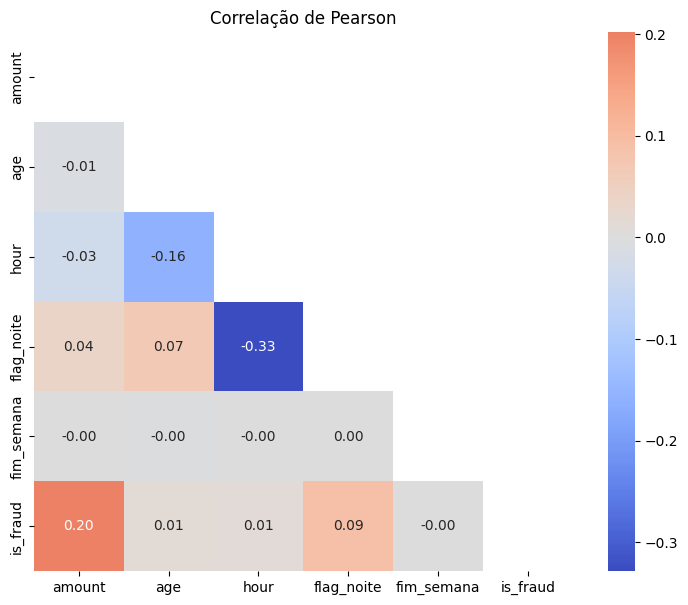

In [9]:
#matriz de correlação (variáveis numéricas)
num_cols = ['amount', 'age', 
            'hour', 'flag_noite', 'fim_semana', 'is_fraud']

corr = df[num_cols].corr(method='pearson')  # spearman é robusto a outliers e a não linearidade monotônica, mas os outliers sao meu caso de interesse. 

mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlação de Pearson')
plt.show()

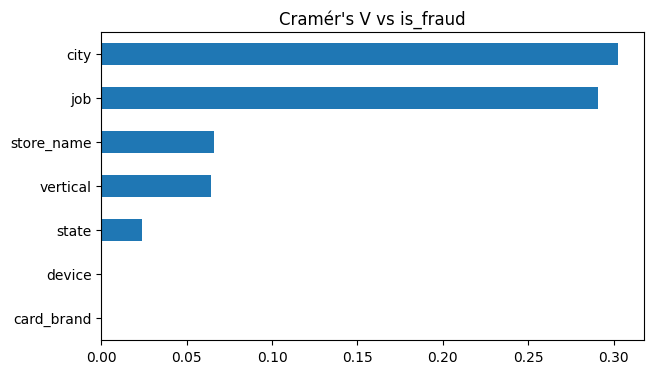

In [10]:
## medida de associação de cramer's V -> é uma especie de "correlação", mas para variáveis categóricas

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    phi2 = chi2 / n
    r, k = ct.shape
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1))

cat_cols = ['store_name', 'vertical', 'device', 'card_brand', 'city', 'state', 'job']
cat_assoc = (pd.Series({c: cramers_v(df[c], df['is_fraud']) for c in cat_cols})
               .sort_values(ascending=False))

cat_assoc.plot(kind='barh', figsize=(7, 4), title="Cramér's V vs is_fraud")
plt.gca().invert_yaxis()
plt.show()

# variáveis candidatas para o modelo inicial:

* amount
* vertical -> transformar em dummie
* device -> transformar em dummie
* card_brand -> dummie
* State -> é um grupo de cidades, por definição. Avaliação de critérios de se e como entrará na análise
* Categorizar população da cidade em (PP/P/M/G/GG ou P/M/G) 
* Idade NA DATA DA COMPRA 
* distância entre o cliente e a loja

## Análise georreferenciada


In [11]:
df.columns

Index(['created_at', 'store_name', 'vertical', 'amount', 'device',
       'card_brand', 'city', 'state', 'lat', 'long', 'city_population', 'job',
       'date_of_birth', 'store_lat', 'store_long', 'is_fraud', 'dist_km',
       'age', 'hour', 'flag_noite', 'dia_semana', 'fim_semana', 'log_amount',
       'log_city_pop', 'state_origem'],
      dtype='object')

In [12]:

stores = (df[['store_name', 'vertical', 'store_lat', 'store_long']]
          .drop_duplicates(subset=['store_name', 'store_lat', 'store_long']))

print('linhas no df:          ', len(df))
print('lojas únicas (nome):   ', df['store_name'].nunique())
print('lojas únicas (nome+coord):', len(stores))

# Quantas coordenadas distintas cada nome de loja tem
coords_por_loja = (df.groupby('store_name')[['store_lat', 'store_long']]
                     .apply(lambda g: g.drop_duplicates().shape[0]))
print(coords_por_loja.describe())

# Diagnostico: em um dataset sintetico, as coordenadas de loja sao calculadas a partir da coordenada do cliente e, por isso a mesma loja tem mais de 1 coordenada. Isso inviabiliza parte da análise 
# que eu planejei. A minha ideia era plotar uma mancha de clientes por vertical de negocio, com pontos para as lojas (totalmente viável em base quente)

linhas no df:           341519
lojas únicas (nome):    693
lojas únicas (nome+coord): 339607
count     693.000000
mean      490.053391
std       155.803266
min       171.000000
25%       403.000000
50%       490.000000
75%       617.000000
max      1149.000000
dtype: float64


Resumo por região


,cidades,compras,fraudes,taxa_fraude_pct
regiao,,,,
Montanhas e Sudoeste,48,102242,480,0.47
Centro,49,89813,483,0.54
Califórnia,40,80948,402,0.50
Noroeste Pacífico,34,61840,356,0.58
Havaí,2,3677,16,0.44
Alasca,4,2999,65,2.17



Top 15 cidades por nº de fraudes (taxa só vale se compras ≥ 200)


,regiao,state,city,lat,long,compras,fraudes,valor_medio,taxa_fraude_pct,pct_compras,pct_fraudes,elegivel_taxa
0,Alasca,AK,Wales,64.76,-165.67,2231,30,68.73,1.34,0.65,1.66,True
1,Montanhas e Sudoeste,NM,Albuquerque,35.10,-106.56,1494,24,79.51,1.61,0.44,1.33,True
2,Montanhas e Sudoeste,CO,Aurora,39.67,-104.83,754,23,78.43,3.05,0.22,1.28,True
3,Montanhas e Sudoeste,WY,Fort Washakie,43.00,-108.90,5145,21,78.12,0.41,1.51,1.17,True
4,Califórnia,CA,Glendale,34.16,-118.23,3673,20,67.62,0.54,1.08,1.11,True
5,Centro,NE,Hubbell,40.05,-97.47,19,19,443.79,100.00,0.01,1.05,False
6,Noroeste Pacífico,WA,Seattle,47.61,-122.29,19,19,682.39,100.00,0.01,1.05,False
7,Califórnia,CA,San Jose,37.33,-121.79,2942,18,56.01,0.61,0.86,1.00,True
8,Califórnia,CA,San Diego,32.95,-117.09,3678,18,71.81,0.49,1.08,1.00,True
9,Montanhas e Sudoeste,AZ,Phoenix,33.66,-112.08,7345,17,72.34,0.23,2.15,0.94,True


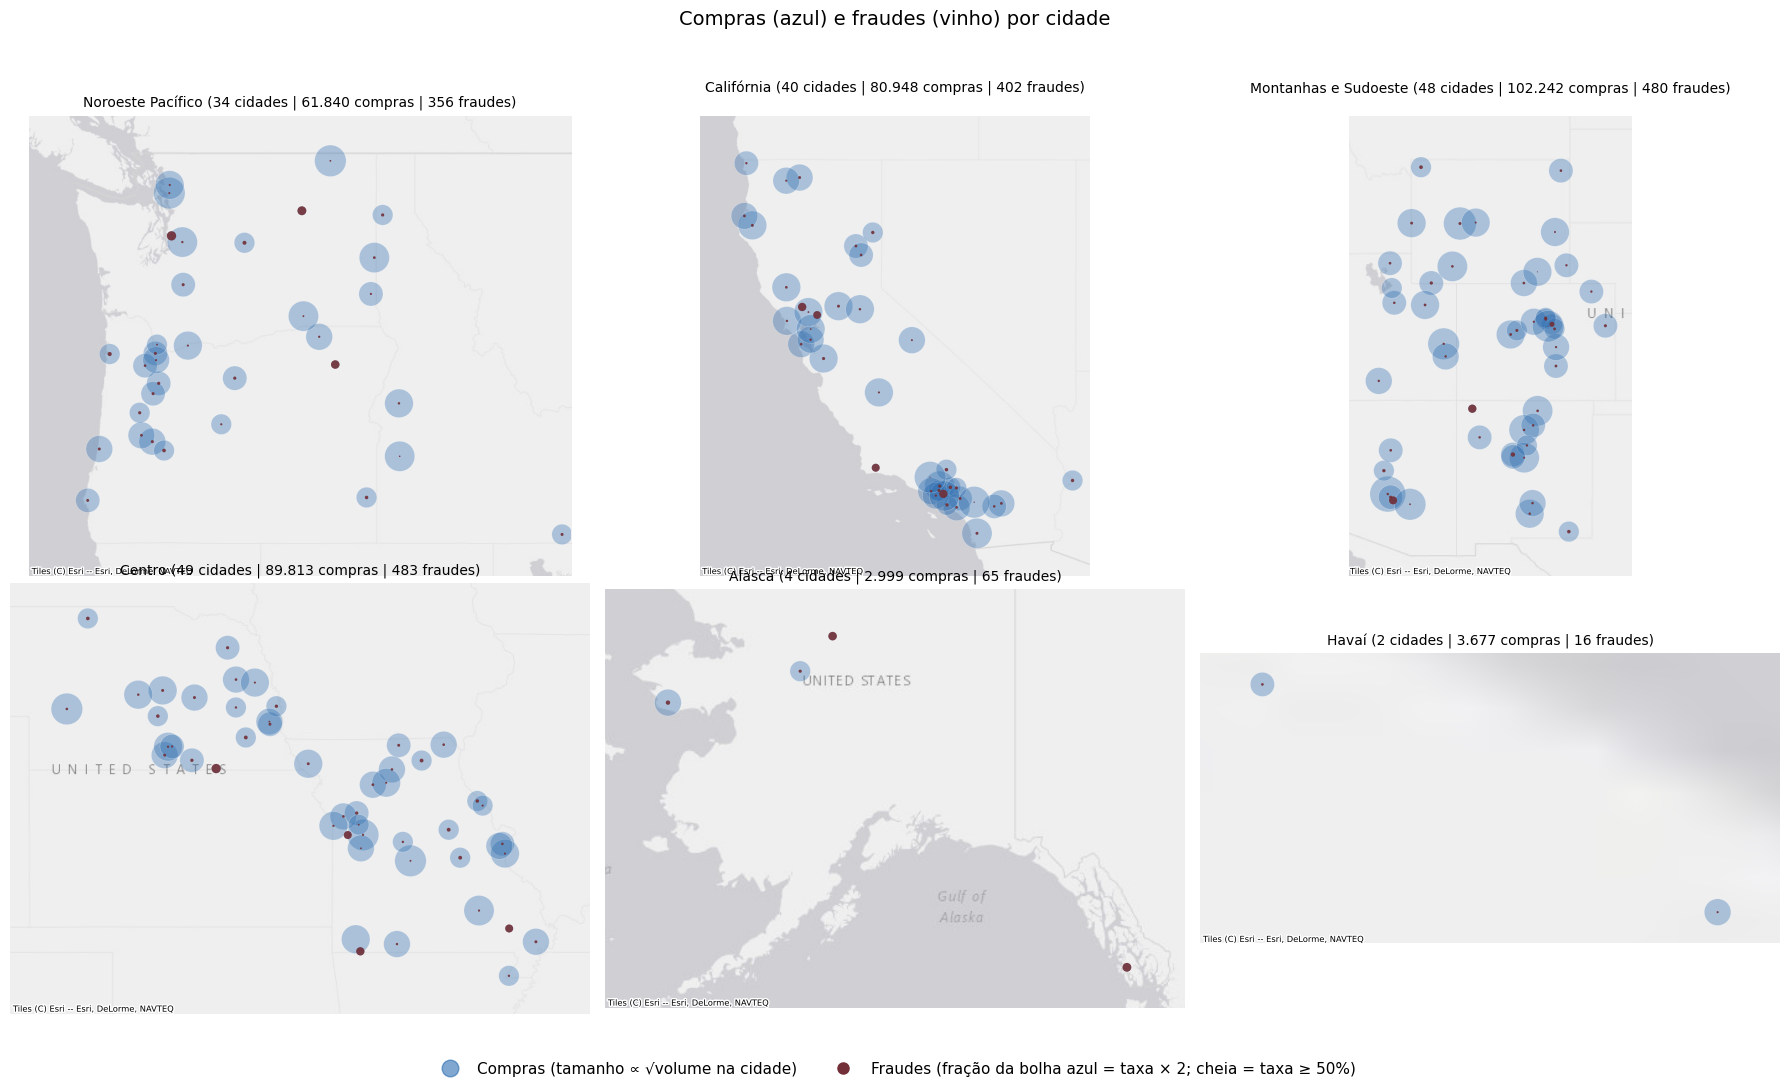

In [13]:
### Análise de % chargeback por cidade
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as cx

AZUL, VINHO = '#2B6CB0', '#722F37'
MIN_COMPRAS = 200   # mínimo de compras para a taxa da cidade ser interpretável
K_FRAUDE = 2       # 1% de fraude preenche 20% da área da bolha azul (teto: 100%)

# ------------------------------------------------------------
# 1) Regiões
# ------------------------------------------------------------
regioes = {
    'Noroeste Pacífico':    ['WA', 'OR', 'ID'],
    'Califórnia':           ['CA'],
    'Montanhas e Sudoeste': ['CO', 'UT', 'WY', 'NM', 'AZ'],
    'Centro':               ['NE', 'MO'],
    'Alasca':               ['AK'],
    'Havaí':                ['HI'],
}
uf2reg = {uf: r for r, ufs in regioes.items() for uf in ufs}
ZOOM = {'Noroeste Pacífico': 6, 'Califórnia': 6, 'Montanhas e Sudoeste': 5,
        'Centro': 6, 'Alasca': 4, 'Havaí': 7}

df = df.copy()
df['regiao'] = df['state'].map(uf2reg)

# Estado nulo: região do centroide mais próximo
cent = df.dropna(subset=['regiao']).groupby('regiao')[['lat', 'long']].mean()
sem = df['regiao'].isna() & df['lat'].notna() & df['long'].notna()
d2 = ((df.loc[sem, 'lat'].values[:, None] - cent['lat'].values[None, :]) ** 2 +
      (df.loc[sem, 'long'].values[:, None] - cent['long'].values[None, :]) ** 2)
df.loc[sem, 'regiao'] = cent.index.values[d2.argmin(axis=1)]

fora = df.loc[df['state'].notna() & ~df['state'].isin(uf2reg), 'state'].value_counts()
if len(fora):
    print('UFs fora do dicionário:'); print(fora)

# ------------------------------------------------------------
# 2) Tabelas auxiliares
# ------------------------------------------------------------
def to_merc(d, x, y):
    return gpd.GeoDataFrame(d.copy(), geometry=gpd.points_from_xy(d[x], d[y]),
                            crs='EPSG:4326').to_crs(3857)

# 2a) Por cidade
cid = (df.groupby(['regiao', 'state', 'city'], dropna=False)
         .agg(lat=('lat', 'mean'), long=('long', 'mean'),
              compras=('is_fraud', 'size'), fraudes=('is_fraud', 'sum'),
              valor_medio=('amount', 'mean'))
         .reset_index()
         .dropna(subset=['lat', 'long', 'regiao']))
cid['taxa_fraude_pct'] = cid['fraudes'] / cid['compras'] * 100
cid['pct_compras'] = cid['compras'] / cid['compras'].sum() * 100
cid['pct_fraudes'] = cid['fraudes'] / cid['fraudes'].sum() * 100
cid['elegivel_taxa'] = cid['compras'] >= MIN_COMPRAS
cid = cid.sort_values('fraudes', ascending=False).reset_index(drop=True)

# 2b) Por região
reg = (cid.groupby('regiao')
          .agg(cidades=('city', 'nunique'), compras=('compras', 'sum'),
               fraudes=('fraudes', 'sum'))
          .assign(taxa_fraude_pct=lambda t: t['fraudes'] / t['compras'] * 100)
          .sort_values('compras', ascending=False)
          .round(2))

print('Resumo por região'); display(reg)
print(f'\nTop 15 cidades por nº de fraudes (taxa só vale se compras ≥ {MIN_COMPRAS})')
display(cid.head(15).round(2))

# Exporta no formato do Excel brasileiro
cid.round(3).to_csv('tabela_cidades_fraude.csv', index=False, sep=';', decimal=',',
                    encoding='utf-8-sig')
reg.to_csv('tabela_regioes_fraude.csv', sep=';', decimal=',', encoding='utf-8-sig')

# ------------------------------------------------------------
# 3) Mapa
# ------------------------------------------------------------
g_ci = to_merc(cid, 'long', 'lat')
n_max = cid['compras'].max()

def s_compras(n):
    return 12 + 650 * np.sqrt(n / n_max)

def s_fraudes(n, f):
    # fração da área da bolha azul: taxa x K_FRAUDE, com teto em 100%
    taxa = np.where(n > 0, f / n, 0)
    return s_compras(n) * np.clip(taxa * K_FRAUDE, 0, 1)

def plot_regiao(ax, nome):
    sub = g_ci[g_ci['regiao'] == nome]
    x, y = sub.geometry.x.values, sub.geometry.y.values
    n_c, n_f = sub['compras'].values, sub['fraudes'].values

    xmin, xmax = np.percentile(x, [1, 99]); ymin, ymax = np.percentile(y, [1, 99])
    px, py = (xmax - xmin) * 0.15 + 1, (ymax - ymin) * 0.15 + 1
    ax.set_xlim(xmin - px, xmax + px); ax.set_ylim(ymin - py, ymax + py)
    ax.set_aspect('equal')

    ax.scatter(x, y, s=s_compras(n_c), c=AZUL, alpha=0.35,
               edgecolor='white', linewidth=0.4, zorder=2)
    ax.scatter(x, y, s=s_fraudes(n_c, n_f), c=VINHO, alpha=0.9,
               edgecolor='none', zorder=3)

    try:
        cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, crs='EPSG:3857',
                       zorder=0, zoom=ZOOM.get(nome), attribution_size=6)
    except Exception as e:
        print(f'[{nome}] basemap não carregou: {e}')

    ax.set_axis_off()
    ax.set_title(f"{nome} ({len(sub)} cidades | {int(n_c.sum()):,} compras | "
                 f"{int(n_f.sum()):,} fraudes)".replace(',', '.'), fontsize=10)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, nome in zip(axes.ravel(), regioes):
    plot_regiao(ax, nome)

handles = [
    plt.Line2D([], [], marker='o', ls='', color=AZUL, alpha=0.6, markersize=12,
               label='Compras (tamanho ∝ √volume na cidade)'),
    plt.Line2D([], [], marker='o', ls='', color=VINHO, markersize=8,
               label=f'Fraudes (fração da bolha azul = taxa × {K_FRAUDE}; '
                     f'cheia = taxa ≥ {100 / K_FRAUDE:.0f}%)'),
]
fig.legend(handles=handles, loc='lower center', ncol=2, frameon=False, fontsize=11)
fig.suptitle('Compras (azul) e fraudes (vinho) por cidade', fontsize=14)
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()

Base: 341.519 compras | 1.802 fraudes | taxa basal = 0.528%

Vertical vs. fraude


,vertical,n,fraudes,peso_pct,taxa_pct,taxa_resto_pct,lift,rr_vs_resto,rr_ic95_inf,rr_ic95_sup,ic95_inf_pct,ic95_sup_pct,phi,p_valor,q_valor_fdr,signif,sinal
0,shopping_net,26538,386,7.77,1.455,0.450,2.76,3.24,2.89,3.62,1.317,1.606,0.0371,3.10e-74,4.34e-73,***,↑ risco acima do resto
1,grocery_pos,32927,437,9.64,1.327,0.442,2.52,3.00,2.70,3.34,1.209,1.457,0.0360,3.48e-73,2.44e-72,***,↑ risco acima do resto
2,misc_net,17008,219,4.98,1.288,0.488,2.44,2.64,2.29,3.04,1.129,1.468,0.0240,3.82e-33,1.78e-32,***,↑ risco acima do resto
3,home,32702,50,9.58,0.153,0.567,0.29,0.27,0.20,0.36,0.116,0.201,-0.0168,6.44e-30,2.26e-29,***,↓ risco abaixo do resto
4,kids_pets,29860,56,8.74,0.188,0.560,0.36,0.33,0.26,0.44,0.144,0.243,-0.0145,8.13e-22,2.28e-21,***,↓ risco abaixo do resto
5,food_dining,23156,38,6.78,0.164,0.554,0.31,0.30,0.21,0.41,0.120,0.225,-0.0135,1.05e-19,2.44e-19,***,↓ risco abaixo do resto
6,health_fitness,22708,37,6.65,0.163,0.554,0.31,0.29,0.21,0.41,0.118,0.224,-0.0134,1.82e-19,3.64e-19,***,↓ risco abaixo do resto
7,personal_care,24542,55,7.19,0.224,0.551,0.42,0.41,0.31,0.53,0.172,0.292,-0.0117,4.03e-14,7.06e-14,***,↓ risco abaixo do resto
8,entertainment,24329,55,7.12,0.226,0.551,0.43,0.41,0.31,0.54,0.174,0.294,-0.0115,9.18e-14,1.43e-13,***,↓ risco abaixo do resto
9,grocery_net,11426,28,3.35,0.245,0.537,0.46,0.46,0.31,0.66,0.170,0.354,-0.0073,3.77e-06,5.27e-06,***,↓ risco abaixo do resto



State vs. fraude


,state,n,fraudes,peso_pct,taxa_pct,taxa_resto_pct,lift,rr_vs_resto,rr_ic95_inf,rr_ic95_sup,ic95_inf_pct,ic95_sup_pct,phi,p_valor,q_valor_fdr,signif,sinal
0,AK,2999,65,0.88,2.167,0.513,4.11,4.22,3.31,5.40,1.704,2.753,0.0213,6.56e-21,8.53e-20,***,↑ risco acima do resto
1,OR,26570,197,7.78,0.741,0.510,1.41,1.45,1.26,1.69,0.645,0.852,0.0086,1.81e-06,1.18e-05,***,↑ risco acima do resto
2,WY,27929,119,8.18,0.426,0.537,0.81,0.79,0.66,0.96,0.356,0.510,-0.0042,1.39e-02,4.53e-02,*,↓ risco abaixo do resto
3,NE,34607,216,10.13,0.624,0.517,1.18,1.21,1.05,1.39,0.546,0.713,0.0045,1.09e-02,4.53e-02,*,↑ risco acima do resto
4,UT,15430,61,4.52,0.395,0.534,0.75,0.74,0.57,0.96,0.308,0.507,-0.0040,1.95e-02,5.08e-02,ns,— sem evidência
5,AZ,15458,64,4.53,0.414,0.533,0.78,0.78,0.61,1.00,0.324,0.528,-0.0034,4.65e-02,1.01e-01,ns,— sem evidência
6,MO,55206,267,16.16,0.484,0.536,0.92,0.90,0.79,1.03,0.429,0.545,-0.0027,1.24e-01,2.15e-01,ns,— sem evidência
7,CA,80948,402,23.70,0.497,0.537,0.94,0.92,0.83,1.03,0.450,0.547,-0.0024,1.65e-01,2.15e-01,ns,— sem evidência
8,ID,8079,33,2.37,0.408,0.531,0.77,0.77,0.55,1.09,0.291,0.573,-0.0026,1.61e-01,2.15e-01,ns,— sem evidência
9,WA,27191,126,7.96,0.463,0.533,0.88,0.87,0.73,1.04,0.389,0.551,-0.0026,1.38e-01,2.15e-01,ns,— sem evidência


Relação lift x RR confere: True

Associação global com is_fraud


,cramers_v,p_valor_chi2,signif
vertical,0.0644,2.73e-298,***
state,0.0239,1.24e-37,***
vertical_state,0.0733,1.98e-306,***



Células testadas: 182 | significativas (FDR<0.05): 60


,vertical,state,n,fraudes,peso_pct,taxa_pct,taxa_resto_pct,lift,rr_vs_resto,rr_ic95_inf,rr_ic95_sup,ic95_inf_pct,ic95_sup_pct,phi,p_valor,q_valor_fdr,signif,sinal,interpretavel
0,grocery_pos,CA,7976,116,2.34,1.454,0.505,2.76,2.88,2.39,3.47,1.214,1.741,0.0198,8.94e-22,1.63e-19,***,↑ risco acima do resto,True
1,grocery_pos,OR,2582,52,0.76,2.014,0.516,3.82,3.90,2.97,5.13,1.539,2.631,0.0179,9.71e-16,8.84e-14,***,↑ risco acima do resto,True
2,shopping_net,OR,2015,44,0.59,2.184,0.518,4.14,4.22,3.14,5.67,1.631,2.919,0.0176,9.84e-15,5.97e-13,***,↑ risco acima do resto,True
3,home,CA,7957,5,2.33,0.063,0.539,0.12,0.12,0.05,0.28,0.027,0.147,-0.0099,1.03e-12,4.68e-11,***,↓ risco abaixo do resto,True
4,shopping_net,CA,6107,79,1.79,1.294,0.514,2.45,2.52,2.01,3.15,1.039,1.609,0.0143,1.42e-12,5.16e-11,***,↑ risco acima do resto,True
5,shopping_net,NE,2615,46,0.77,1.759,0.518,3.33,3.39,2.54,4.54,1.321,2.338,0.0149,4.34e-12,1.32e-10,***,↑ risco acima do resto,True
6,shopping_net,AK,244,15,0.07,6.148,0.524,11.65,11.74,7.17,19.21,3.761,9.894,0.0207,6.69e-12,1.74e-10,***,↑ risco acima do resto,True
7,shopping_net,NM,1789,36,0.52,2.012,0.520,3.81,3.87,2.79,5.37,1.457,2.773,0.0149,2.43e-11,5.54e-10,***,↑ risco acima do resto,True
8,grocery_pos,CO,1993,35,0.58,1.756,0.520,3.33,3.37,2.42,4.70,1.265,2.432,0.0130,1.57e-09,3.17e-08,***,↑ risco acima do resto,True
9,misc_net,CA,3785,50,1.11,1.321,0.519,2.50,2.55,1.93,3.37,1.003,1.737,0.0116,1.00e-08,1.69e-07,***,↑ risco acima do resto,True


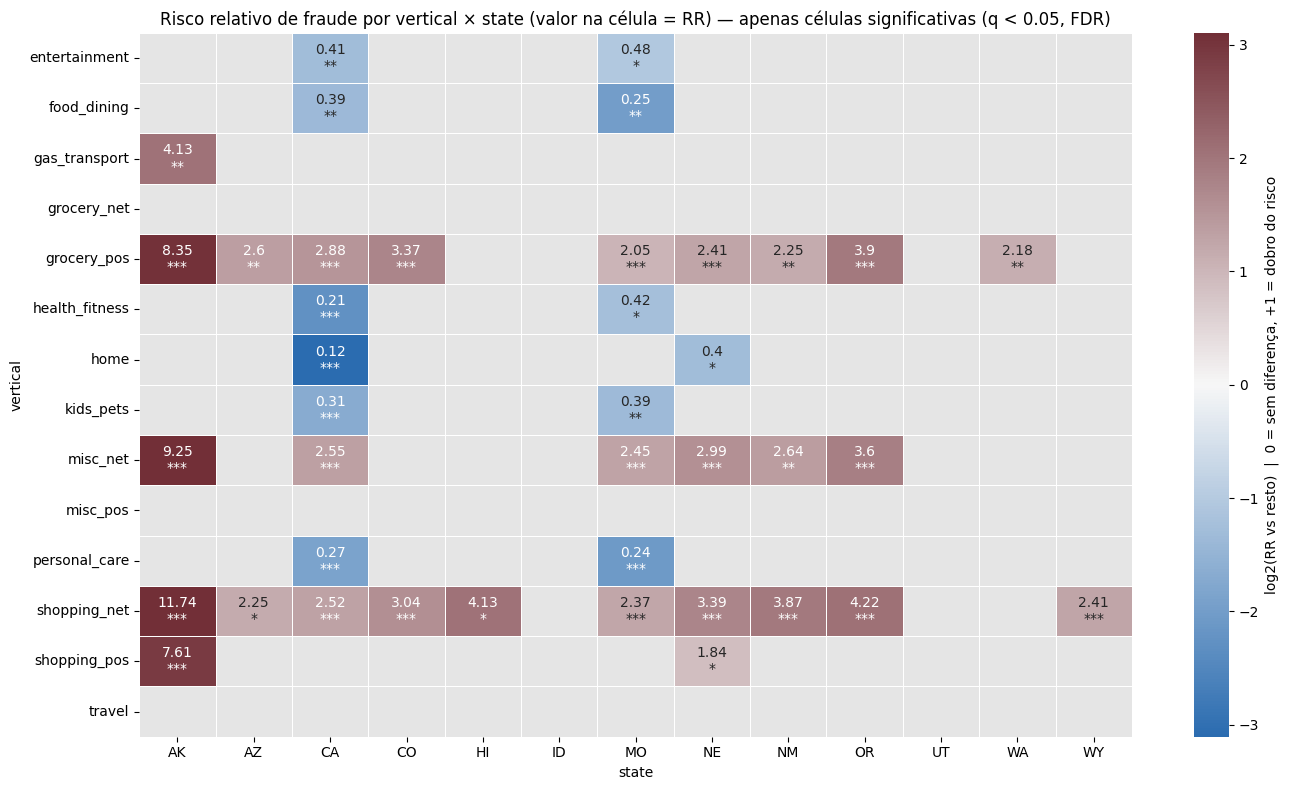

In [14]:


AZUL, VINHO = '#2B6CB0', '#722F37'
ALPHA = 0.05
MIN_FRAUDES = 5
Z = 1.96

d = df[['vertical', 'state', 'is_fraud']].copy()
d['state'] = d['state'].fillna('(nulo)')
d['vertical'] = d['vertical'].fillna('(nulo)')

N, F = len(d), d['is_fraud'].sum()
P0 = F / N
print(f'Base: {N:,} compras | {F:,} fraudes | taxa basal = {P0*100:.3f}%'.replace(',', '.'))

def estrelas(q):
    return '***' if q < 0.001 else '**' if q < 0.01 else '*' if q < ALPHA else 'ns'

def testa_niveis(d, cols):
    cols = [cols] if isinstance(cols, str) else cols
    g = (d.groupby(cols, observed=True)['is_fraud']
           .agg(n='size', fraudes='sum').reset_index())
    a = g['fraudes'].astype(float)      # nível, fraude
    b = g['n'] - a                      # nível, não fraude
    c = F - a                           # resto, fraude
    e = (N - g['n']) - c                # resto, não fraude

    g['peso_pct'] = g['n'] / N * 100
    g['taxa_pct'] = a / g['n'] * 100
    g['taxa_resto_pct'] = c / (N - g['n']) * 100

    # Lift: P(fraude | nível) / P(fraude na base inteira)
    g['lift'] = (a / g['n']) / P0

    # Risco relativo contra o resto: mesma escala do teste de Fisher
    g['rr_vs_resto'] = (a / g['n']) / (c / (N - g['n']))
    with np.errstate(divide='ignore', invalid='ignore'):
        se = np.sqrt(1 / a - 1 / g['n'] + 1 / c - 1 / (N - g['n']))
        g['rr_ic95_inf'] = np.exp(np.log(g['rr_vs_resto']) - Z * se)
        g['rr_ic95_sup'] = np.exp(np.log(g['rr_vs_resto']) + Z * se)

    lo, hi = proportion_confint(a, g['n'], method='wilson')
    g['ic95_inf_pct'], g['ic95_sup_pct'] = lo * 100, hi * 100

    den = np.sqrt((a + b) * (c + e) * (a + c) * (b + e))
    g['phi'] = (a * e - b * c) / den

    g['p_valor'] = [fisher_exact([[ai, bi], [ci, ei]])[1]
                    for ai, bi, ci, ei in zip(a, b, c, e)]
    g['q_valor_fdr'] = multipletests(g['p_valor'], method='fdr_bh')[1]
    g['signif'] = g['q_valor_fdr'].map(estrelas)
    g['sinal'] = np.where(g['q_valor_fdr'] >= ALPHA, '— sem evidência',
                  np.where(g['rr_vs_resto'] > 1, '↑ risco acima do resto', '↓ risco abaixo do resto'))
    return g.sort_values('q_valor_fdr').reset_index(drop=True)

tab_vert = testa_niveis(d, 'vertical')
tab_state = testa_niveis(d, 'state')

fmt = {'peso_pct': '{:.2f}', 'taxa_pct': '{:.3f}', 'taxa_resto_pct': '{:.3f}',
       'lift': '{:.2f}', 'rr_vs_resto': '{:.2f}', 'rr_ic95_inf': '{:.2f}', 'rr_ic95_sup': '{:.2f}',
       'ic95_inf_pct': '{:.3f}', 'ic95_sup_pct': '{:.3f}',
       'phi': '{:.4f}', 'p_valor': '{:.2e}', 'q_valor_fdr': '{:.2e}'}
print('\nVertical vs. fraude'); display(tab_vert.style.format(fmt))
print('\nState vs. fraude');    display(tab_state.style.format(fmt))

# Verificação da relação lift = RR / (w·RR + 1 − w)
w = tab_state['n'] / N
chk = tab_state['rr_vs_resto'] / (w * tab_state['rr_vs_resto'] + 1 - w)
print('Relação lift x RR confere:', np.allclose(chk.dropna(), tab_state.loc[chk.notna(), 'lift']))

# ------------------------------------------------------------
# Associação global
# ------------------------------------------------------------
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(ct, correction=False)
    n = ct.values.sum(); r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(kc - 1, rc - 1)), p

d['vertical_state'] = d['vertical'] + ' | ' + d['state']
glob = pd.DataFrame(
    {v: cramers_v(d[v], d['is_fraud']) for v in ['vertical', 'state', 'vertical_state']},
    index=['cramers_v', 'p_valor_chi2']).T
glob['signif'] = glob['p_valor_chi2'].map(estrelas)
print('\nAssociação global com is_fraud')
display(glob.style.format({'cramers_v': '{:.4f}', 'p_valor_chi2': '{:.2e}'}))

# ------------------------------------------------------------
# Matriz vertical x state (RR contra o resto + significância)
# ------------------------------------------------------------
cel = testa_niveis(d, ['vertical', 'state'])
cel['interpretavel'] = cel['fraudes'] >= MIN_FRAUDES

rr_m   = cel.pivot(index='vertical', columns='state', values='rr_vs_resto')
star_m = cel.pivot(index='vertical', columns='state', values='signif')
frd_m  = cel.pivot(index='vertical', columns='state', values='fraudes')

print(f'\nCélulas testadas: {len(cel)} | significativas (FDR<{ALPHA}): {(cel["signif"] != "ns").sum()}')
display(cel[cel['signif'] != 'ns'].head(20).style.format(fmt))

ok = (star_m != 'ns') & (frd_m >= MIN_FRAUDES)
annot = (rr_m.round(2).astype(str) + '\n' + star_m).where(ok, '')

# Escala log2: 0 = sem diferença, +1 = o dobro do risco do resto, -1 = metade
log_rr = np.log2(rr_m.where(ok))
lim = max(1.0, np.nanpercentile(np.abs(log_rr.values), 95))

cmap = LinearSegmentedColormap.from_list('azul_vinho', [AZUL, '#F7F7F7', VINHO])
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(log_rr, annot=annot, fmt='', cmap=cmap, center=0, vmin=-lim, vmax=lim,
            linewidths=0.5, linecolor='white', mask=~ok, ax=ax,
            cbar_kws={'label': 'log2(RR vs resto)  |  0 = sem diferença, +1 = dobro do risco'})
ax.set_facecolor('#E5E5E5')   # cinza: sem evidência ou poucas fraudes
ax.set_title(f'Risco relativo de fraude por vertical × state (valor na célula = RR) — '
             f'apenas células significativas (q < {ALPHA}, FDR)')
plt.tight_layout(); plt.show()

# Avaliação do tamanho das cidades


In [15]:

d = df[['city', 'state', 'city_population', 'lat', 'long', 'is_fraud', 'amount']].copy()

# 1) Consistência: quantos valores de população por cidade?
pop_por_cidade = d.groupby(['state', 'city'], dropna=False)['city_population'].nunique()
print('Cidades:', len(pop_por_cidade))
print(pop_por_cidade.describe())
print('Cidades com mais de 1 valor de população:', (pop_por_cidade > 1).sum())

Cidades: 177
count    177.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: city_population, dtype: float64
Cidades com mais de 1 valor de população: 0


In [16]:
cidades = (df.groupby(['state', 'city'], observed=True)['city_population']
             .median()
             .reset_index())

# Checagens
print('Cidades:', len(cidades))
print('Duplicatas em (state, city):', cidades.duplicated(['state', 'city']).sum())
print('Nulos:', cidades.isna().sum().to_dict())
print('Nomes repetidos entre estados:', cidades['city'].duplicated().sum())

# A mediana só é equivalente ao valor original se houver 1 população por cidade
n_pop = df.groupby(['state', 'city'])['city_population'].nunique()
print('Cidades com mais de 1 valor de população:', (n_pop > 1).sum())

display(cidades.sort_values('city_population', ascending=False).head())

Cidades: 177
Duplicatas em (state, city): 0
Nulos: {'state': 0, 'city': 0, 'city_population': 0}
Nomes repetidos entre estados: 1
Cidades com mais de 1 valor de população: 0


,state,city,city_population
31,CA,Los Angeles,2383912.0
8,AZ,Phoenix,1312922.0
41,CA,San Diego,1241364.0
42,CA,San Jose,973849.0
90,MO,Saint Louis,927396.0


In [17]:
cidades.shape

(177, 3)

In [18]:
labels = ['PP', 'P', 'M', 'G', 'GG']

# 1) Quintis no nível de cidade
cidades = cidades.drop(columns='size_city', errors='ignore')
cidades['size_city'], edges = pd.qcut(cidades['city_population'], q=5, labels=labels,
                                      retbins=True, duplicates='raise')
cidades['size_city'] = cidades['size_city'].astype(pd.CategoricalDtype(labels, ordered=True))

print('Cortes (população):', [f'{e:,.0f}'.replace(',', '.') for e in edges])

# 2) Perfil das faixas (nível cidade)
perfil = (cidades.groupby('size_city', observed=False)['city_population']
                 .agg(cidades='size', pop_min='min', pop_mediana='median', pop_max='max'))
print(perfil.to_string())

# 3) Leva a categoria para o df de transações (chave: state + city)
df = df.drop(columns='size_city', errors='ignore')
df = df.merge(cidades[['state', 'city', 'size_city']], on=['state', 'city'], how='left')

# 4) Conferências
print('Nulos em size_city:', df['size_city'].isna().sum(), '| linhas no df:', len(df))

P0 = df['is_fraud'].mean()
resumo = (df.groupby('size_city', observed=False)['is_fraud']
            .agg(compras='size', fraudes='sum'))

print(resumo.round(3).to_string())

Cortes (população): ['46', '343', '1.037', '3.925', '79.226', '2.383.912']
           cidades  pop_min  pop_mediana    pop_max
size_city                                          
PP              36     46.0        202.0      337.0
P               35    369.0        633.0     1019.0
M               35   1063.0       1725.0     3805.0
G               35   4005.0      13983.0    59705.0
GG              36  84106.0     212406.5  2383912.0
Nulos em size_city: 0 | linhas no df: 341519
           compras  fraudes
size_city                  
PP           76568      385
P            63353      357
M            66966      364
G            64706      311
GG           69926      385


In [19]:
df.columns

Index(['created_at', 'store_name', 'vertical', 'amount', 'device',
       'card_brand', 'city', 'state', 'lat', 'long', 'city_population', 'job',
       'date_of_birth', 'store_lat', 'store_long', 'is_fraud', 'dist_km',
       'age', 'hour', 'flag_noite', 'dia_semana', 'fim_semana', 'log_amount',
       'log_city_pop', 'state_origem', 'regiao', 'size_city'],
      dtype='object')

# variáveis candidatas para o modelo inicial:

* amount -> ENTRA
* vertical -> transformar em dummie -> ENTRA
* device -> transformar em dummie -> ENTRA
* card_brand -> dummie -> ENTRA
* State -> ENTRA COMO DUMMIES
* Categorizar população da cidade em PP/P/M/G/GG
* Idade NA DATA DA COMPRA -> ENTRA
* distância entre o cliente e a loja -> NAO ENTRA POIS O DATASET É SINTETICO E A LOCALIZAÇÃO DA LOJA É UMA FUNÇÃO DA LOCALIZAÇÃO DO CLIENTE
+ features derivadas: 'hour', 'flag_noite', 'dia_semana', 'fim_semana'

In [20]:
df.columns

Index(['created_at', 'store_name', 'vertical', 'amount', 'device',
       'card_brand', 'city', 'state', 'lat', 'long', 'city_population', 'job',
       'date_of_birth', 'store_lat', 'store_long', 'is_fraud', 'dist_km',
       'age', 'hour', 'flag_noite', 'dia_semana', 'fim_semana', 'log_amount',
       'log_city_pop', 'state_origem', 'regiao', 'size_city'],
      dtype='object')

In [21]:
### df_final completo
TARGET = 'is_fraud'

# Numéricas que entram como estão
num_cols = ['amount', 'age', 'hour', 'flag_noite', 'fim_semana']

# Categóricas que viram dummies
# (size_city é ordinal; aqui entra como dummies, ver nota abaixo)
cat_cols = ['vertical', 'device', 'card_brand', 'state', 'size_city', 'dia_semana']

# Garante que os nulos não passem para o modelo
base = df[num_cols + cat_cols + [TARGET]].copy()
print('Nulos por coluna:\n', base.isna().sum()[base.isna().sum() > 0])

# dia_semana e size_city como texto/categoria para gerar nomes legíveis
base['dia_semana'] = base['dia_semana'].astype(int).astype(str)
base['size_city'] = base['size_city'].astype(str)

df_final = pd.get_dummies(base, columns=cat_cols, prefix=cat_cols,
                          drop_first=True, dtype=int)

# Conferências
print('Formato:', df_final.shape)
print('Taxa de fraude:', round(df_final[TARGET].mean() * 100, 3), '%')
print('Colunas proibidas presentes:',
      [c for c in ['dist_km', 'store_lat', 'store_long', 'regiao', 'state_origem']
       if c in df_final.columns])
print(df_final.columns.tolist())

Nulos por coluna:
 Series([], dtype: int64)
Formato: (341519, 44)
Taxa de fraude: 0.528 %
Colunas proibidas presentes: []
['amount', 'age', 'hour', 'flag_noite', 'fim_semana', 'is_fraud', 'vertical_food_dining', 'vertical_gas_transport', 'vertical_grocery_net', 'vertical_grocery_pos', 'vertical_health_fitness', 'vertical_home', 'vertical_kids_pets', 'vertical_misc_net', 'vertical_misc_pos', 'vertical_personal_care', 'vertical_shopping_net', 'vertical_shopping_pos', 'vertical_travel', 'device_Web', 'card_brand_Master Card', 'card_brand_Visa', 'state_AZ', 'state_CA', 'state_CO', 'state_HI', 'state_ID', 'state_MO', 'state_NE', 'state_NM', 'state_OR', 'state_UT', 'state_WA', 'state_WY', 'size_city_GG', 'size_city_M', 'size_city_P', 'size_city_PP', 'dia_semana_1', 'dia_semana_2', 'dia_semana_3', 'dia_semana_4', 'dia_semana_5', 'dia_semana_6']


In [22]:
from sklearn.model_selection import train_test_split

TARGET = 'is_fraud'
SEED = 1710

X = df_final.drop(columns=TARGET)
y = df_final[TARGET]

# 1) Separa o teste (20%), que só será usado no final
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)

# Conferências
for nome, yy in [('treino', y_train), ('validação', y_val), ('teste', y_test)]:
    print(f'{nome:10s} | linhas: {len(yy):>7,} | fraudes: {int(yy.sum()):>5,} | '
          f'taxa: {yy.mean()*100:.3f}%'.replace(',', '.'))

assert len(X_train) + len(X_val) + len(X_test) == len(X)
assert not (set(X_train.index) & set(X_val.index) | set(X_train.index) & set(X_test.index)
            | set(X_val.index) & set(X_test.index)), 'índices repetidos entre os conjuntos'

treino     | linhas: 204.911 | fraudes: 1.081 | taxa: 0.528%
validação  | linhas:  68.304 | fraudes:   361 | taxa: 0.529%
teste      | linhas:  68.304 | fraudes:   360 | taxa: 0.527%


In [23]:
#Modelo Inicial: Regressão Logistica


import time
import warnings
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, accuracy_score, f1_score,
                             roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)

RESULTADOS, CURVAS, MODELOS, FIGURAS = [], {}, {}, {}

def limiar_max_f1(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return thr[f1.argmax()]

def avalia(nome, modelo, Xtr=None, ytr=None, Xav=None, yav=None, limiar_f1=None):
    """Treina `modelo` em (Xtr, ytr) e avalia em (Xav, yav). Padrão: treino e validação.
    No teste, passe limiar_f1 escolhido na validação, para não otimizar no teste."""
    Xtr = X_train if Xtr is None else Xtr
    ytr = y_train if ytr is None else ytr
    Xav = X_val if Xav is None else Xav
    yav = y_val if yav is None else yav

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        t = time.time()
        modelo.fit(Xtr, ytr)
        dur = time.time() - t

    p = modelo.predict_proba(Xav)[:, 1]
    roc_auc, pr_auc = roc_auc_score(yav, p), average_precision_score(yav, p)
    lim_f1 = limiar_max_f1(yav, p) if limiar_f1 is None else limiar_f1

    linhas = []
    for criterio, lim in [('0,5', 0.5), ('max F1', lim_f1)]:
        yhat = (p >= lim).astype(int)
        linhas.append({
            'modelo': nome, 'limiar_criterio': criterio, 'limiar': round(float(lim), 4),
            'precision': round(precision_score(yav, yhat, zero_division=0), 4),
            'recall': round(recall_score(yav, yhat), 4),
            'accuracy': round(accuracy_score(yav, yhat), 4),
            'f1': round(f1_score(yav, yhat, zero_division=0), 4),
            'roc_auc': round(roc_auc, 4), 'pr_auc': round(pr_auc, 4),
            'iter': int(np.max(modelo.n_iter_)), 'tempo_s': round(dur, 1),
            'avisos': '; '.join(sorted({w.category.__name__ for w in avisos})) or '-',
        })

    MODELOS[nome] = modelo
    RESULTADOS.extend(linhas)
    CURVAS[nome] = {'y': yav, 'p': p, 'roc_auc': roc_auc, 'pr_auc': pr_auc}
    return modelo

def resumo():
    print(f'Prevalência na validação: {y_val.mean():.4f}')
    display(pd.DataFrame(RESULTADOS))

def plota_curvas(curvas_dict=None):
    curvas_dict = CURVAS if curvas_dict is None else curvas_dict
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5))
    for nome, c in curvas_dict.items():
        fpr, tpr, _ = roc_curve(c['y'], c['p'])
        prec, rec, _ = precision_recall_curve(c['y'], c['p'])
        a1.plot(fpr, tpr, label=f"{nome} (AUC={c['roc_auc']:.3f})")
        a2.plot(rec, prec, label=f"{nome} (PR-AUC={c['pr_auc']:.3f})")
    a1.plot([0, 1], [0, 1], 'k--', lw=0.8, label='aleatório')
    a2.axhline(next(iter(curvas_dict.values()))['y'].mean(), color='k', ls='--', lw=0.8,
               label='prevalência')
    a1.set(xlabel='Taxa de falsos positivos', ylabel='Recall (TPR)', title='Curva ROC')
    a2.set(xlabel='Recall', ylabel='Precisão', title='Curva precisão-recall')
    a1.legend(fontsize=7); a2.legend(fontsize=7)
    plt.tight_layout(); plt.show()

In [24]:

print(f'Baseline (prevalência na validação): {y_val.mean():.4f}')
m_simples  = avalia('sem pesos', LogisticRegression(max_iter=5000))
m_no_interc = avalia('Sem intercepto', LogisticRegression(fit_intercept=False, max_iter=5000))

# The “balanced” mode uses the values of y to automatically adjust weights inversely proportional to class frequencies in the input data as n_samples / (n_classes * np.bincount(y)).
m_balanced = avalia('class_weight balanced', LogisticRegression(class_weight='balanced', max_iter=5000))
m_balanced_nointerc = avalia('class_weight balanced e sem intercepto', LogisticRegression(fit_intercept=False, class_weight='balanced', max_iter=5000))
m_balanced_newtn_cholesky = avalia('class_weight balanced solver = newton-cholesky', LogisticRegression(class_weight='balanced', max_iter=7000, solver = 'newton-cholesky'))



Baseline (prevalência na validação): 0.0053


In [25]:
from IPython.display import display
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve

def inspeciona(nome, modelo=None, top=15, X_ref=None):
    """Mostra tudo o que foi gerado para um modelo e devolve os objetos num dicionário."""
    X_ref = X_train if X_ref is None else X_ref
    modelo = MODELOS.get(nome) if modelo is None else modelo
    c = CURVAS[nome]
    y, p = np.asarray(c['y']), np.asarray(c['p'])

    # 1) Métricas (última execução de cada limiar)
    met = (pd.DataFrame(RESULTADOS).query('modelo == @nome')
             .drop_duplicates(['limiar_criterio', 'limiar'], keep='last')
             .drop(columns='modelo').reset_index(drop=True))
    print(f'=== {nome} ===')
    print(f"ROC-AUC: {c['roc_auc']:.4f} | PR-AUC: {c['pr_auc']:.4f} | prevalência: {y.mean():.4f}")
    display(met)

    # 2) Matriz de confusão em cada limiar reportado
    conf = {}
    for _, r in met.iterrows():
        yh = (p >= r['limiar']).astype(int)
        cm = confusion_matrix(y, yh)
        conf[f"{r['limiar_criterio']} ({r['limiar']})"] = pd.DataFrame(
            cm, index=['real: não fraude', 'real: fraude'],
            columns=['prev: não fraude', 'prev: fraude'])
    for k, v in conf.items():
        print(f'\nMatriz de confusão, limiar {k}'); display(v)

    # 3) Distribuição dos scores por classe
    print('\nScores por classe real')
    display(pd.Series(p).groupby(y).describe(percentiles=[.5, .9, .99]).round(4))

    # 4) Parâmetros e coeficientes
    coef = None
    if modelo is not None:
        print('\nParâmetros:', modelo.get_params())
        if hasattr(modelo, 'coef_'):
            print('Intercepto:', modelo.intercept_.round(4), '| iterações:', modelo.n_iter_)
            coef = (pd.DataFrame({'coef': modelo.coef_[0], 'odds_ratio': np.exp(modelo.coef_[0])},
                                 index=X_ref.columns)
                      .sort_values('coef', key=abs, ascending=False))
            titulo = 'coeficientes (odds ratio por unidade da variável)'
        else:
            coef = (pd.DataFrame({'importancia_split': modelo.feature_importances_,
                                  'importancia_gain': modelo.booster_.feature_importance('gain')},
                                 index=X_ref.columns)
                      .sort_values('importancia_gain', ascending=False))
            titulo = 'importâncias (gain = ganho total de cada variável nas divisões)'
        print(f'\nTop {top} {titulo}')
        display(coef.head(top).round(4))
    else:
        print('\nModelo não guardado em MODELOS: passe modelo=<variável> para ver coeficientes.')
    

    # 5) Figura (guardada ou reconstruída)
    fig = globals().get('FIGURAS', {}).get(nome)
    if fig is not None:
        display(fig)
    else:
        fpr, tpr, _ = roc_curve(y, p); prec, rec, _ = precision_recall_curve(y, p)
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5))
        a1.plot(fpr, tpr); a1.plot([0, 1], [0, 1], 'k--', lw=.8)
        a1.set(title=f"ROC (AUC={c['roc_auc']:.3f})", xlabel='FPR', ylabel='Recall')
        a2.plot(rec, prec); a2.axhline(y.mean(), color='k', ls='--', lw=.8)
        a2.set(title=f"Precisão-recall (PR-AUC={c['pr_auc']:.3f})", xlabel='Recall', ylabel='Precisão')
        plt.tight_layout(); plt.show()

    return {'modelo': modelo, 'metricas': met, 'confusao': conf, 'coef': coef,
            'y': y, 'p': p, 'figura': fig}

In [26]:
from lightgbm import LGBMClassifier

m_lgbm = avalia('lgbm balanced',
                LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                               min_child_samples=50, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, class_weight='balanced',
                               random_state=42, verbose=-1))

In [27]:
# Tabela de métricas de todas as chamadas
df_res = pd.DataFrame(RESULTADOS)
df_res.query("limiar_criterio == 'max F1'").sort_values('pr_auc', ascending=False)

,modelo,limiar_criterio,limiar,precision,recall,accuracy,f1,roc_auc,pr_auc,iter,tempo_s,avisos
11,lgbm balanced,max F1,0.9456,0.9021,0.8172,0.9986,0.8576,0.9980,0.9107,300,9.4,-
1,sem pesos,max F1,0.1419,0.6166,0.3296,0.9954,0.4296,0.9035,0.2708,811,83.4,DeprecationWarning
9,class_weight balanced solver = newton-cholesky,max F1,0.9627,0.3539,0.4598,0.9927,0.4000,0.9492,0.2099,7,3.9,-
5,class_weight balanced,max F1,0.9614,0.3516,0.4626,0.9927,0.3995,0.9492,0.2092,1640,184.5,DeprecationWarning
7,class_weight balanced e sem intercepto,max F1,0.9652,0.2964,0.4598,0.9914,0.3605,0.9440,0.1929,1947,204.0,DeprecationWarning
3,Sem intercepto,max F1,0.1072,0.2727,0.2493,0.9925,0.2605,0.8745,0.1374,967,99.7,DeprecationWarning


=== lgbm balanced ===
ROC-AUC: 0.9980 | PR-AUC: 0.9107 | prevalência: 0.0053


,limiar_criterio,limiar,precision,recall,accuracy,f1,roc_auc,pr_auc,iter,tempo_s,avisos
0,"0,5",0.5000,0.4891,0.9335,0.9945,0.6419,0.998,0.9107,300,9.4,-
1,max F1,0.9456,0.9021,0.8172,0.9986,0.8576,0.998,0.9107,300,9.4,-



Matriz de confusão, limiar 0,5 (0.5)


,prev: não fraude,prev: fraude
real: não fraude,67591,352
real: fraude,24,337



Matriz de confusão, limiar max F1 (0.9456)


,prev: não fraude,prev: fraude
real: não fraude,67911,32
real: fraude,67,294



Scores por classe real


,count,mean,std,min,50%,90%,99%,max
0,67943.0,0.0089,0.0613,0.0000,0.0004,0.0040,0.2457,0.9981
1,361.0,0.9195,0.2134,0.0068,0.9980,0.9994,0.9997,0.9997



Parâmetros: {'boosting_type': 'gbdt', 'class_weight': 'balanced', 'colsample_bytree': 0.8, 'importance_type': 'split', 'learning_rate': 0.05, 'max_depth': -1, 'min_child_samples': 50, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 300, 'n_jobs': None, 'num_leaves': 31, 'objective': None, 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 0.8, 'subsample_for_bin': 200000, 'subsample_freq': 1, 'verbose': -1}

Top 15 importâncias (gain = ganho total de cada variável nas divisões)


,importancia_split,importancia_gain
amount,2031,1.535146e+06
flag_noite,168,2.222690e+05
hour,885,1.129188e+05
age,1951,1.037494e+05
vertical_gas_transport,178,5.971926e+04
vertical_food_dining,170,4.316176e+04
vertical_travel,192,2.764126e+04
vertical_misc_pos,210,2.744308e+04
vertical_home,177,2.719095e+04
vertical_grocery_pos,164,2.532680e+04


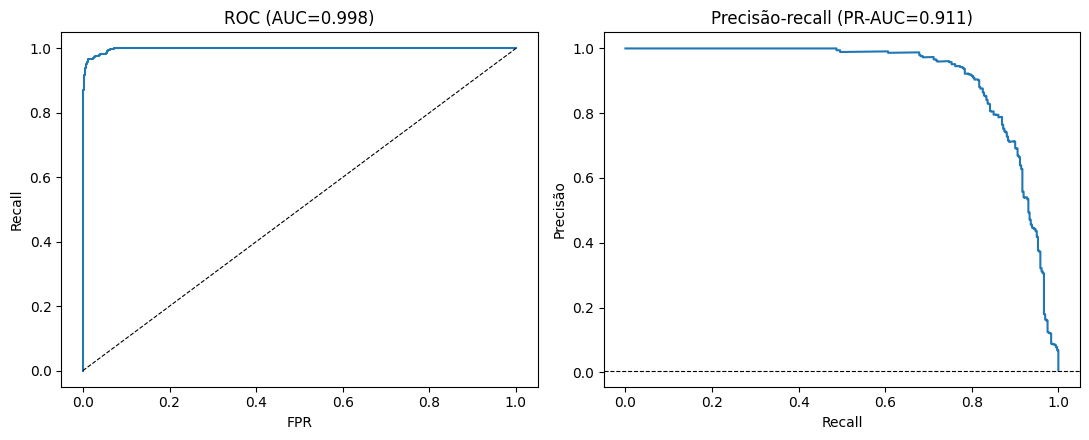

In [28]:
r2 = inspeciona('lgbm balanced')

=== class_weight balanced solver = newton-cholesky ===
ROC-AUC: 0.9492 | PR-AUC: 0.2099 | prevalência: 0.0053


,limiar_criterio,limiar,precision,recall,accuracy,f1,roc_auc,pr_auc,iter,tempo_s,avisos
0,"0,5",0.5000,0.0309,0.8753,0.8544,0.0598,0.9492,0.2099,7,3.9,-
1,max F1,0.9627,0.3539,0.4598,0.9927,0.4000,0.9492,0.2099,7,3.9,-



Matriz de confusão, limiar 0,5 (0.5)


,prev: não fraude,prev: fraude
real: não fraude,58043,9900
real: fraude,45,316



Matriz de confusão, limiar max F1 (0.9627)


,prev: não fraude,prev: fraude
real: não fraude,67640,303
real: fraude,195,166



Scores por classe real


,count,mean,std,min,50%,90%,99%,max
0,67943.0,0.1691,0.2336,0.0002,0.0580,0.5955,0.8714,1.0
1,361.0,0.8188,0.2411,0.0247,0.9403,0.9991,0.9999,1.0



Parâmetros: {'C': 1.0, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 7000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': None, 'solver': 'newton-cholesky', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Intercepto: [-5.4434] | iterações: [7]

Top 15 coeficientes (odds ratio por unidade da variável)


,coef,odds_ratio
vertical_gas_transport,3.6370,37.9763
vertical_grocery_net,3.0897,21.9703
vertical_travel,2.8683,17.6078
flag_noite,2.8271,16.8967
vertical_grocery_pos,2.6833,14.6333
vertical_misc_pos,2.4027,11.0528
vertical_health_fitness,2.3545,10.5330
vertical_personal_care,2.1960,8.9894
vertical_kids_pets,2.1142,8.2833
state_HI,-1.9965,0.1358


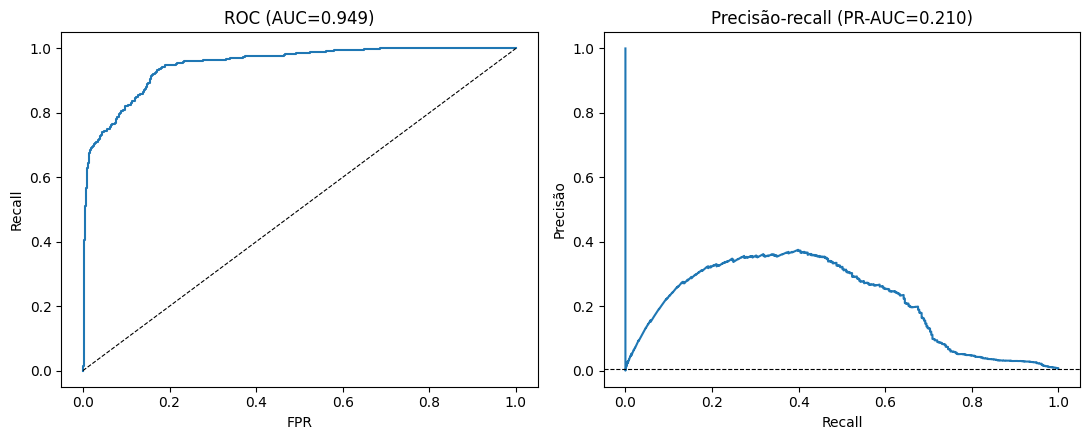

In [29]:
r = inspeciona('class_weight balanced solver = newton-cholesky')

In [30]:
from sklearn.base import clone

nome_val = 'lgbm balanced'     # nome com que o modelo foi avaliado na validação

# 1) Limiar de max F1 escolhido na validação (última execução desse modelo)
lim = (pd.DataFrame(RESULTADOS)
         .query("modelo == @nome_val and limiar_criterio == 'max F1'")['limiar'].iloc[-1])
print(f'Limiar fixado na validação: {lim:.4f}')

# 2) Mesmo modelo, mesmos hiperparâmetros, avaliado no teste
m_teste = avalia(f'TESTE | {nome_val}',
                 clone(MODELOS[nome_val]),
                 Xav=X_test, yav=y_test, limiar_f1=lim)

Limiar fixado na validação: 0.9456


In [31]:
res = pd.DataFrame(RESULTADOS)
nome_teste = f'TESTE | {nome_val}'
cols = ['precision', 'recall', 'f1', 'pr_auc', 'roc_auc']

def ultima(nome):
    return (res[(res['modelo'] == nome) & (res['limiar_criterio'] == 'max F1')]
              [cols].iloc[[-1]])

display(pd.concat([ultima(nome_val).assign(base='validação'),
                   ultima(nome_teste).assign(base='teste')]).set_index('base'))

,precision,recall,f1,pr_auc,roc_auc
base,,,,,
validação,0.9021,0.8172,0.8576,0.9107,0.9980
teste,0.9211,0.8111,0.8626,0.8998,0.9963


In [32]:
## Modelo Campeão: LIGHTGBM
import os, json, joblib, sklearn, lightgbm
from datetime import datetime

# Pasta onde estão os dados (ajuste para o caminho que você usa no read_csv)
PASTA = '/content/drive/MyDrive/fraude'      # ex.: ou os.path.dirname(caminho_do_csv)
os.makedirs(PASTA, exist_ok=True)

NOME = 'lgbm balanced'
modelo = MODELOS[NOME]

# Limiar de max F1 fixado na validação (o mesmo aplicado no teste)
limiar = float(pd.DataFrame(RESULTADOS)
                 .query("modelo == @NOME and limiar_criterio == 'max F1'")['limiar'].iloc[-1])

teste = (pd.DataFrame(RESULTADOS)
           .query("modelo == 'TESTE | lgbm balanced' and limiar_criterio == 'max F1'")
           .iloc[-1])

artefato = {
    'modelo': modelo,
    'colunas': list(X_train.columns),      # ordem exata das features no treino
    'limiar': limiar,
    'criterio_limiar': 'max F1 na validação',
    'metricas_teste': {k: float(teste[k]) for k in ['precision', 'recall', 'f1', 'pr_auc', 'roc_auc']},
    'versoes': {'sklearn': sklearn.__version__, 'lightgbm': lightgbm.__version__},
    'criado_em': datetime.now().isoformat(timespec='seconds'),
}

joblib.dump(artefato, os.path.join(PASTA, 'modelo_campeao_lgbm.joblib'))

# Metadados legíveis, sem o objeto do modelo
meta = {k: v for k, v in artefato.items() if k != 'modelo'}
meta['hiperparametros'] = modelo.get_params()
with open(os.path.join(PASTA, 'modelo_campeao_lgbm_meta.json'), 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2, default=str)

print('Salvo em:', PASTA)
print(os.listdir(PASTA))

Salvo em: /content/drive/MyDrive/fraude
['modelo_campeao_lgbm_meta.json', 'modelo_campeao_lgbm.joblib']


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


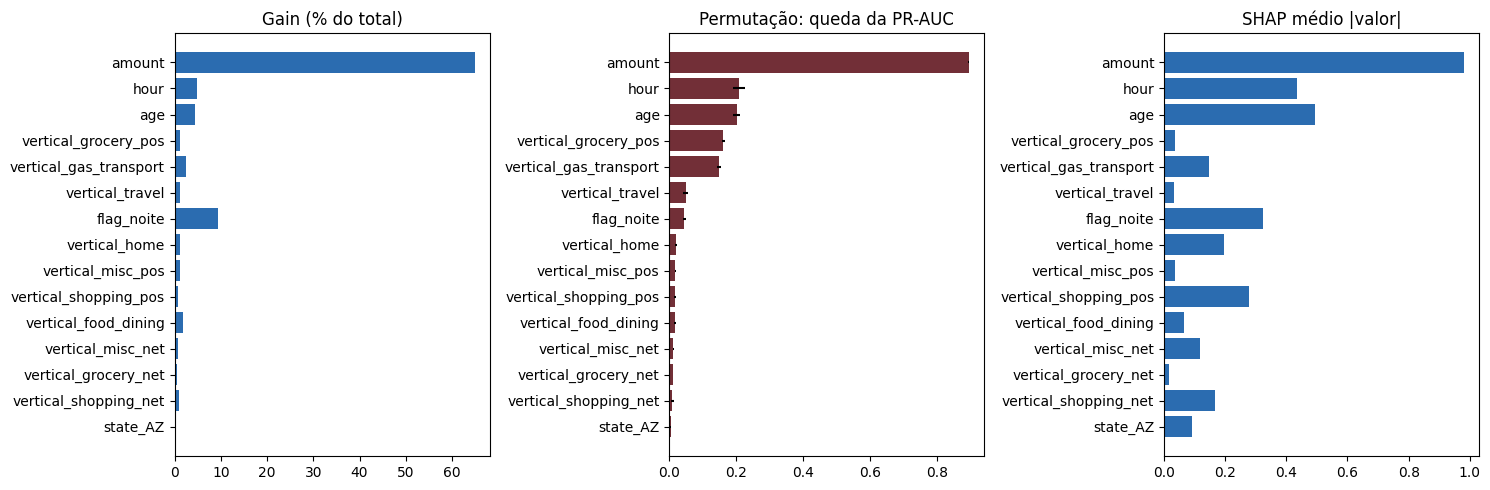

,gain_%,split_%,perm_queda_prauc,perm_desvio,shap_medio_abs
amount,64.9280,22.5667,0.8934,0.0024,0.9810
hour,4.7758,9.8333,0.2078,0.0167,0.4361
age,4.3880,21.6778,0.2006,0.0107,0.4939
vertical_grocery_pos,1.0712,1.8222,0.1612,0.0053,0.0354
vertical_gas_transport,2.5258,1.9778,0.1480,0.0062,0.1471
vertical_travel,1.1691,2.1333,0.0491,0.0074,0.0335
flag_noite,9.4007,1.8667,0.0448,0.0038,0.3242
vertical_home,1.1500,1.9667,0.0198,0.0028,0.1950
vertical_misc_pos,1.1607,2.3333,0.0181,0.0017,0.0363
vertical_shopping_pos,0.8117,1.4556,0.0159,0.0027,0.2787


In [33]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

def importancia_features(modelo, X, y, n_repeats=5, amostra_shap=1000, top=15, seed=42):
    """Importância do modelo: gain, split, permutação (PR-AUC) e SHAP. Use X, y da VALIDAÇÃO."""
    out = pd.DataFrame(index=list(X.columns))

    # 1) Importância nativa do LightGBM
    b = modelo.booster_
    out['gain_%']  = 100 * b.feature_importance('gain')  / b.feature_importance('gain').sum()
    out['split_%'] = 100 * b.feature_importance('split') / b.feature_importance('split').sum()

    # 2) Permutação: quanto a PR-AUC cai ao embaralhar cada feature
    pi = permutation_importance(modelo, X, y, scoring='average_precision',
                                n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    out['perm_queda_prauc'] = pi.importances_mean
    out['perm_desvio']      = pi.importances_std

    # 3) SHAP (opcional, precisa do pacote shap)
    shap_ok = False
    try:
        import shap
        Xs = X.sample(min(amostra_shap, len(X)), random_state=seed)
        sv = shap.TreeExplainer(modelo).shap_values(Xs)
        if isinstance(sv, list): sv = sv[1]
        sv = np.asarray(sv)
        if sv.ndim == 3: sv = sv[:, :, 1]
        out['shap_medio_abs'] = np.abs(sv).mean(axis=0)
        shap_ok = True
    except Exception as e:
        print('SHAP indisponível:', e)

    out = out.sort_values('perm_queda_prauc', ascending=False)
    t = out.head(top).iloc[::-1]
    fig, ax = plt.subplots(1, 3 if shap_ok else 2, figsize=(15, 5))
    ax[0].barh(t.index, t['gain_%'], color='#2B6CB0'); ax[0].set_title('Gain (% do total)')
    ax[1].barh(t.index, t['perm_queda_prauc'], xerr=t['perm_desvio'], color='#722F37')
    ax[1].set_title('Permutação: queda da PR-AUC')
    if shap_ok:
        ax[2].barh(t.index, t['shap_medio_abs'], color='#2B6CB0'); ax[2].set_title('SHAP médio |valor|')
    plt.tight_layout(); plt.show()
    return out

imp = importancia_features(modelo, X_val, y_val)
imp.round(4)

In [34]:
#avaliação de custos do modelo

def avalia_custo(nome, X=None, y=None, limiar=None):
    """Custo do modelo `nome` no limiar de max F1 escolhido na validação.
    Padrão: validação. Para o teste, passe X=X_test, y=y_test (o limiar continua o da validação)."""
    X = X_val if X is None else X
    y = y_val if y is None else y

    # Limiar de max F1 fixado na validação (última execução do modelo)
    if limiar is None:
        r = pd.DataFrame(RESULTADOS)
        limiar = float(r[(r['modelo'] == nome) & (r['limiar_criterio'] == 'max F1')]['limiar'].iloc[-1])

    p = MODELOS[nome].predict_proba(X)[:, 1]
    yv = np.asarray(y)
    a = df.loc[y.index, 'amount'].values.astype(float)

    def custo(yh):
        fn = (yv == 1) & ~yh
        fp = (yv == 0) & yh
        tp = (yv == 1) & yh
        aprov = ~yh                                  # transações aprovadas (não barradas)
        n_aprov = int(aprov.sum())
        v_aprov = a[aprov].sum()
        return {
            'TP': int(tp.sum()), 'FP': int(fp.sum()), 'FN': int(fn.sum()),
            'valor_chargeback': a[fn].sum(),        # FN: fraude não barrada
            'valor_venda_perdida': a[fp].sum(),     # FP: venda não concluída
            'custo_total': a[fn].sum() + a[fp].sum(),
            'recall_valor': a[tp].sum() / a[yv == 1].sum(),
            # % chargeback sobre o aprovado, em quantidade e em valor
            'pct_chargeback_qtd': fn.sum() / n_aprov * 100 if n_aprov else np.nan,
            'pct_chargeback_valor': a[fn].sum() / v_aprov * 100 if v_aprov else np.nan,
            # contexto: quanto do volume o modelo deixou passar
            'taxa_aprovacao_pct': n_aprov / len(yv) * 100,
        }

    modelo_c = custo(p >= limiar)
    sem_modelo = custo(np.zeros(len(yv), dtype=bool))   # aprova tudo: toda fraude vira chargeback

    tab = pd.DataFrame({'sem modelo': sem_modelo, f'{nome} (max F1 = {limiar:.3f})': modelo_c}).T
    tab['economia'] = sem_modelo['custo_total'] - tab['custo_total']
    tab['economia_pct'] = tab['economia'] / sem_modelo['custo_total'] * 100
    # redução relativa do % de chargeback (em valor) frente ao cenário sem modelo
    tab['reducao_pct_chargeback_valor'] = (
        (sem_modelo['pct_chargeback_valor'] - tab['pct_chargeback_valor'])
        / sem_modelo['pct_chargeback_valor'] * 100
    )

    print(f'Custo | {nome} | {len(yv):,} transações | fraudes: {int(yv.sum())}'.replace(',', '.'))
    display(tab.round(2))
    return tab

In [35]:
tab_val = avalia_custo('lgbm balanced')

Custo | lgbm balanced | 68.304 transações | fraudes: 361


,TP,FP,FN,valor_chargeback,valor_venda_perdida,custo_total,recall_valor,pct_chargeback_qtd,pct_chargeback_valor,taxa_aprovacao_pct,economia,economia_pct,reducao_pct_chargeback_valor
sem modelo,0.0,0.0,361.0,178075.05,0.00,178075.05,0.00,0.53,3.74,100.00,0.00,0.00,0.00
lgbm balanced (max F1 = 0.946),294.0,32.0,67.0,10435.81,29183.23,39619.04,0.94,0.10,0.23,99.52,138456.01,77.75,93.89


In [36]:
print("quantidade de Transações: ", X_val['amount'].count())
print("Valor das Transações: ", X_val['amount'].sum())
print("% chargeback - sem modelo")



quantidade de Transações:  68304
Valor das Transações:  4763744.52
% chargeback - sem modelo


In [37]:
tab_te  = avalia_custo('lgbm balanced', X=X_test, y=y_test)      # teste, mesmo limiar

Custo | lgbm balanced | 68.304 transações | fraudes: 360


,TP,FP,FN,valor_chargeback,valor_venda_perdida,custo_total,recall_valor,pct_chargeback_qtd,pct_chargeback_valor,taxa_aprovacao_pct,economia,economia_pct,reducao_pct_chargeback_valor
sem modelo,0.0,0.0,360.0,187678.95,0.00,187678.95,0.00,0.53,3.87,100.00,0.00,0.00,0.00
lgbm balanced (max F1 = 0.946),292.0,25.0,68.0,12691.52,15804.18,28495.70,0.93,0.10,0.27,99.54,159183.25,84.82,92.96


In [38]:
import numpy as np
import pandas as pd

def indicadores(nome, X=None, y=None, limiar=None):
    """Índice de chargeback financeiro e taxa de aprovação no limiar de max F1 da validação."""
    X = X_val if X is None else X
    y = y_val if y is None else y

    if limiar is None:
        r = pd.DataFrame(RESULTADOS)
        limiar = float(r[(r['modelo'] == nome) & (r['limiar_criterio'] == 'max F1')]['limiar'].iloc[-1])

    p = MODELOS[nome].predict_proba(X)[:, 1]
    yv = np.asarray(y)
    a = df.loc[y.index, 'amount'].values.astype(float)

    def calc(aprovada):
        fn = aprovada & (yv == 1)                       # fraude aprovada = chargeback
        return {
            'Índice de chargeback financeiro (%)': a[fn].sum() / a[aprovada].sum() * 100,
            'Taxa de aprovação, por valor (%)': a[aprovada].sum() / a.sum() * 100,
            'Taxa de aprovação, por quantidade (%)': aprovada.mean() * 100,
            'Chargeback (valor)': a[fn].sum(),
            'Vendas aprovadas (valor)': a[aprovada].sum(),
        }

    return pd.DataFrame({
        'sem modelo (aprova tudo)': calc(np.ones(len(yv), dtype=bool)),
        f'{nome} (max F1 = {limiar:.3f})': calc(p < limiar),
    }).T.round(3)

lim = float(pd.DataFrame(RESULTADOS).query("modelo == 'lgbm balanced' and limiar_criterio == 'max F1'")['limiar'].iloc[-1])

print('Validação'); display(indicadores('lgbm balanced'))
print('Teste (limiar fixado na validação)'); display(indicadores('lgbm balanced', X=X_test, y=y_test, limiar=lim))
print('Teste (limiar fixado na validação)'); display(indicadores('lgbm balanced', X=X_val, y=y_val, limiar=lim))

Validação


,Índice de chargeback financeiro (%),"Taxa de aprovação, por valor (%)","Taxa de aprovação, por quantidade (%)",Chargeback (valor),Vendas aprovadas (valor)
sem modelo (aprova tudo),3.738,100.000,100.000,178075.05,4763744.52
lgbm balanced (max F1 = 0.946),0.229,95.868,99.523,10435.81,4566922.05


Teste (limiar fixado na validação)


,Índice de chargeback financeiro (%),"Taxa de aprovação, por valor (%)","Taxa de aprovação, por quantidade (%)",Chargeback (valor),Vendas aprovadas (valor)
sem modelo (aprova tudo),3.872,100.000,100.000,187678.95,4847546.92
lgbm balanced (max F1 = 0.946),0.273,96.064,99.536,12691.52,4656755.31


Teste (limiar fixado na validação)


,Índice de chargeback financeiro (%),"Taxa de aprovação, por valor (%)","Taxa de aprovação, por quantidade (%)",Chargeback (valor),Vendas aprovadas (valor)
sem modelo (aprova tudo),3.738,100.000,100.000,178075.05,4763744.52
lgbm balanced (max F1 = 0.946),0.229,95.868,99.523,10435.81,4566922.05


Arquitetura & MLOps em Produção (Visão ponta-a-ponta)
Explique brevemente na sua apresentação/documentação como abordaria a operacionalização do modelo:
#### 1. Deploy & Serving: Como a predição seria servida no momento do checkout (ex: API em tempo real com baixa latência)?
Como é um modelo de ML Clássico (LightGBM), ele consegue fazer um predict em questão de milisegundos. o arquivo .joblib já é gerado n o código para ser inserido em uma imagem de container, com versionamento. O método de operacionalização, se usando APIRestr ou outra ferramenta, depende da arquitetura pré-definida da empresa.
No case, o limiar de aprovação foi definido de forma a maximizar o F1 score e atribuido como parametro. Assim, se a area de negocio decidir mudar apenas o limiar, não há a necessidade de retreino

Falback: em caso de falha do modelo, é preciso estabeler regras de decisao estáticas para aprovação automatica, a serem definidas pela área de negócio.

Periodo de implementação: rodar o modelo em modo sombra e acompanhar as curvas de chargeback nas semanas seguintes, salvando os scores e acompanhando o chargeback diariamente.
Como o chargeback é um evento que nao temos o retorno on time do processamento, levando dias e até semanas para se concretizar, o acompanhamento precisará cobrir essa janela.
Registro: cada predição grava o ID da transação, as features usadas, o score, a versão do modelo e a decisão. Esse log é a base do monitoramento e do retreino.

#### 2. Feature Store: Como garantir a consistência das features entre treino e inferência em tempo real?

é preciso garantir consistencia no calculo das features do modelo, principalmente das variáveis derivadas: hora da compra, fim de semana, dia da semana, flag_noite.
a classificação da cidade em pp-p-m-g-gg deve ser construida separadamente e salva em banco de dados para consumo do modelo. como é um dado basicamente estático (atualização anual pelos orgaos competentes, sem grandes variações), deve-se criar uma rotina anual de verificação/atualização dos dados dessa tabela (No caso do brasil, há uma consulta por API pelo site do IBGE pronta, com a estimativa populacional de cada municipio)

#### 3. Monitoramento & Governança de ML
As metricas de avaliação do modelo já foram construidas como funçoes para facilitar a implementação em produção/ uso do MLflow.

em tempo real, acompanhamos o valor transacionado e a quantidade de transações hora a hora frente as features do modelo (hora da compra, cidade, vertical, etc) e frente ao numero de transações rejeitadas. COnstruimos tambem uma visao de carta-controle para alarmar volumes fora do padrão, usando testes estatisticos para validação (KS para variaveis numericas e Qui-quadrado para categoricas; outros testes podem ser necessários)

#### 4. Se o fluxo for batch (predições em lotes): Como seguiria?

Não faz sentido prever em batch uma verificação de fraude em compra online. O custo de tempo e processamento em tempo real é baixo em relação a experiencia do cliente que ficaria aguardando o proximo lote para aprovar ou nao a compra. O fluxo em batch pode ser uma camada de fallback em caso de problemas na predição em tempo real. 
O fluxo em batch é interessante no periodo de validação do modelo em produção, enquanto estiver em modo sombra